# 02 Gold: star schema, SCD Type 2 page dimension, E(L) marts

Spark SQL writes Gold (`python -m etl.gold_run --as-of ...`). Builds ran in knowledge order: as_of 2026-10-24 (early), 2026-10-27T20:59:59.999999Z (parity), 2026-11-13T23:59:59.999999Z (extended). The checks are in `python -m etl.gold_checks`.

In [1]:
import json, os, sys
from pathlib import Path
REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == 'final' else Path.cwd()
sys.path.insert(0, str(REPO))
os.environ.setdefault('TRUTHLAG_HW2_DIR', str(REPO / 'ec-hw2'))
import pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
from deltalake import DeltaTable
LAKE = REPO / 'data' / 'lake'
RUNS = LAKE / '_runs'
def run(name): return json.loads((RUNS / name).read_text())
def table(name, version=None, columns=None):
    return DeltaTable(str(LAKE / name), version=version).to_pandas(columns=columns)
def history(name, n=10):
    h = DeltaTable(str(LAKE / name)).history(n)
    return pd.DataFrame([{k: e.get(k) for k in ('version', 'operation', 'step', 'as_of', 'snapshot', 'rows')} for e in h])


## Tables, versions and row counts

In [2]:
rows = []
for t in ['dim_cohort', 'dim_snapshot', 'dim_time', 'dim_user', 'dim_page', 'fact_edit', 'fact_revert_label', 'mart_el_curve', 'mart_el_by_burst']:
    dt = DeltaTable(str(LAKE / 'gold' / t))
    rows.append({'table': 'gold/' + t, 'version': dt.version(), 'rows': sum(b.num_rows for b in dt.to_pyarrow_dataset().to_batches(columns=[dt.schema().to_arrow().names[0]])), 'cdf': dt.metadata().configuration.get('delta.enableChangeDataFeed')})
pd.DataFrame(rows)

,table,version,rows,cdf
0,gold/dim_cohort,1,3,None
1,gold/dim_snapshot,1,1,None
2,gold/dim_time,2,33118,None
3,gold/dim_user,2,185465,None
4,gold/dim_page,3,2324643,None
5,gold/fact_edit,3,2972220,true
6,gold/fact_revert_label,1,5266843,true
7,gold/mart_el_curve,2,117,None
8,gold/mart_el_by_burst,2,162,None


## Commit history of fact_edit (commit metadata holds step and as_of)

In [3]:
history('gold/fact_edit')

,version,operation,step,as_of,snapshot,rows
0,3,MERGE,None,None,None,None
1,2,MERGE,None,None,None,None
2,1,MERGE,None,None,None,None
3,0,CREATE TABLE,None,None,None,None


## Checks at the parity and the extended as_of

In [4]:
for f in ('gold_checks_parity.json', 'gold_checks_ext.json'):
    g = run(f); print(f, g['passed'], 'of', g['total'], 'passed; versions', g['versions'])
pd.DataFrame(run('gold_checks_ext.json')['checks'])[['check', 'ok']]

gold_checks_parity.json 30 of 30 passed; versions {'dim_page': 2, 'fact_edit': 2, 'fact_revert_label': 1, 'mart_el_curve': 1, 'mart_el_by_burst': 1}
gold_checks_ext.json 30 of 30 passed; versions {'dim_page': 3, 'fact_edit': 3, 'fact_revert_label': 1, 'mart_el_curve': 2, 'mart_el_by_burst': 2}


,check,ok
0,fact_edit history rows,True
1,fact_edit live rows,True
2,fact_edit history rows by user_kind,True
3,fact_edit live rows by user_kind,True
4,mart_el_curve history known by wait (all editors),True
5,mart_el_curve live known by wait (all editors),True
6,live E(1 h) = 0.4205,True
7,history E(1 h) = 0.4434,True
8,live share known at 1 h = 57.95%,True
9,"mart_el_curve history temporary at 1 h (known,...",True


## dim_page (SCD Type 2): one moved page, with its versions

The page with the most versions among history-cohort pages. Titles are page titles (public), not editor names.

In [5]:
dp = table('gold/dim_page')
fe = table('gold/fact_edit', columns=['cohort_id', 'page_key', 'event_dt'])
hist_pages = dp[dp.page_key.isin(fe[fe.cohort_id == 'history'].page_key)].page_id.unique()
n = dp[dp.page_id.isin(hist_pages)].groupby('page_id').size().sort_values(ascending=False)
pid = n.index[0]
dp[dp.page_id == pid].sort_values('valid_from')

,page_key,wiki_db,page_id,title,namespace,is_deleted,valid_from,valid_to,is_current
2174129,76142262-19000101000000,enwiki,76142262,World_Baseball_Classic_television_ratings,0,False,1900-01-01 00:00:00+00:00,2026-10-24 04:35:14+00:00,False
430080,76142262-20261024043514,enwiki,76142262,World_Baseball_Classic_Coverage_and_Attendance,0,False,2026-10-24 04:35:14+00:00,2026-10-24 04:46:08+00:00,False
430081,76142262-20261024044608,enwiki,76142262,World_Baseball_Classic_Coverage_and_Venue,0,False,2026-10-24 04:46:08+00:00,2026-10-24 04:50:58+00:00,False
2174130,76142262-20261024045058,enwiki,76142262,World_Baseball_Classic_Coverage_and_Venues,0,False,2026-10-24 04:50:58+00:00,2026-10-24 07:00:29+00:00,False
430082,76142262-20261024070029,enwiki,76142262,World_Baseball_Classic_Venues,0,False,2026-10-24 07:00:29+00:00,2026-10-24 08:19:09+00:00,False
1010722,76142262-20261024081909,enwiki,76142262,World_Baseball_Classic_Broadcast,0,False,2026-10-24 08:19:09+00:00,2026-10-24 08:42:10+00:00,False
2174131,76142262-20261024084210,enwiki,76142262,World_Baseball_Classic_broadcast,0,False,2026-10-24 08:42:10+00:00,2026-11-03 14:41:29+00:00,False
430083,76142262-20261103144129,enwiki,76142262,World_Baseball_Classic_Participant_game_broadc...,0,False,2026-11-03 14:41:29+00:00,2026-11-03 14:43:52+00:00,False
430084,76142262-20261103144352,enwiki,76142262,Participant_game_broadcasts_of_the_World_Baseb...,0,False,2026-11-03 14:43:52+00:00,2026-11-10 14:21:45+00:00,False
430085,76142262-20261110142145,enwiki,76142262,Success_of_the_Tournament_in_the_World_Basebal...,0,False,2026-11-10 14:21:45+00:00,2026-11-10 14:30:57+00:00,False


## E(L) curve, all editors

In [6]:
el = table('gold/mart_el_curve')
el[el.user_kind == 'all'].pivot_table(index=['wait_s', 'wait_label'], columns='cohort_id', values='e_l').round(4)

,cohort_id,history,live,live_ext
wait_s,wait_label,,,
0,0,1.0000,1.0000,1.0000
60,1 min,0.8013,0.7763,0.7757
300,5 min,0.6484,0.6095,0.6123
900,15 min,0.5615,0.5287,0.5277
3600,1 h,0.4434,0.4205,0.4126
21600,6 h,0.2690,0.2477,0.2470
86400,1 d,0.1104,0.1056,0.0950
172800,2 d,0.0522,0.0628,0.0493
345600,4 d,0.0000,0.0000,0.0000


## E(L) at 1 h by editor kind (kind at edit time); small groups flagged

In [7]:
el[el.wait_label == '1 h'][['cohort_id', 'user_kind', 'n_eventual', 'n_known', 'e_l', 'small_group']].sort_values(['cohort_id', 'user_kind'])

,cohort_id,user_kind,n_eventual,n_known,e_l,small_group
94,history,all,17646,9822,0.443387,False
99,history,bot,157,40,0.745223,False
100,history,registered,7623,3622,0.524859,False
92,history,temporary,9863,6157,0.375748,False
98,history,unknown,3,3,0.000000,True
17,live,all,17818,10326,0.420474,False
21,live,bot,141,40,0.716312,False
23,live,registered,7905,3928,0.503099,False
19,live,temporary,9772,6358,0.349366,False
57,live_ext,all,112937,66344,0.412557,False


## Figure

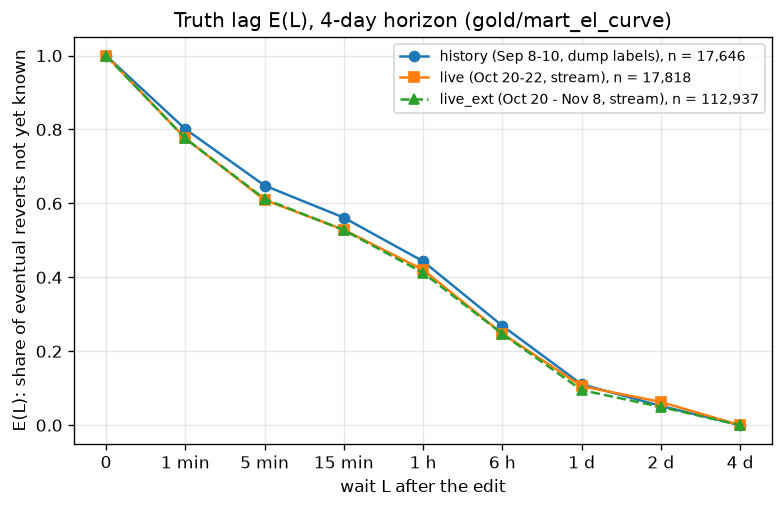

In [8]:
from IPython.display import Image
Image(filename=str(REPO / 'docs/final/figures/el_curve.png'))